In [1]:
import random

L = 24   # grid is L x L
J = 1    # how strongly neighbours want to agree

def make_grid(size, rng):
    # Each spin is +1 (up) or -1 (down), chosen at random.
    return [[rng.choice([-1, 1]) for _ in range(size)] for _ in range(size)]

def show_grid(grid):
    for row in grid:
        print(" ".join("+" if s == 1 else "-" for s in row))

rng = random.Random(17)
small = make_grid(4, rng)

print("A random 4 x 4 grid (+ is up, - is down):")
show_grid(small)

assert all(s in (-1, 1) for row in small for s in row)

A random 4 x 4 grid (+ is up, - is down):
+ + + +
- + - -
- + + +
+ + - -


In [2]:
def neighbour_sum(grid, i, j):
    # Up, down, left and right. The % makes the edges wrap around.
    size = len(grid)
    return (grid[(i - 1) % size][j] + grid[(i + 1) % size][j]
            + grid[i][(j - 1) % size] + grid[i][(j + 1) % size])


# The 2 x 2 grid from Q2: on a wrapped 2 x 2 grid every neighbour appears twice.
q2_grid = [[+1, +1],
           [+1, -1]]

print("S00 =", neighbour_sum(q2_grid, 0, 0))
print("S11 =", neighbour_sum(q2_grid, 1, 1))

assert neighbour_sum(q2_grid, 0, 0) == 4
assert neighbour_sum(q2_grid, 1, 1) == 4

S00 = 4
S11 = 4


In [3]:
def total_energy(grid):
    # Count every bond once: each spin with its right and its lower neighbour.
    size = len(grid)
    energy = 0
    for i in range(size):
        for j in range(size):
            s = grid[i][j]
            energy -= J * s * (grid[i][(j + 1) % size] + grid[(i + 1) % size][j])
    return energy


all_up = [[1, 1], [1, 1]]

print("Energy of the Q2 grid:", total_energy(q2_grid))
print("Energy of the all-up grid:", total_energy(all_up))

assert total_energy(q2_grid) == 0
assert total_energy(all_up) == -8

Energy of the Q2 grid: 0
Energy of the all-up grid: -8


In [4]:
def delta_energy(grid, i, j):
    # Flipping one spin only changes its 4 bonds: dE = 2 * J * s * S
    return 2 * J * grid[i][j] * neighbour_sum(grid, i, j)

def delta_by_recompute(grid, i, j):
    # The slow way: flip, measure the whole grid, flip back.
    before = total_energy(grid)
    grid[i][j] = -grid[i][j]
    after = total_energy(grid)
    grid[i][j] = -grid[i][j]
    return after - before


print("Flip s00: local", delta_energy(q2_grid, 0, 0), " recompute", delta_by_recompute(q2_grid, 0, 0))
print("Flip s11: local", delta_energy(q2_grid, 1, 1), " recompute", delta_by_recompute(q2_grid, 1, 1))

assert delta_energy(q2_grid, 0, 0) == 8
assert delta_energy(q2_grid, 1, 1) == -8

# Check the shortcut against the slow way on many random grids.
check_rng = random.Random(1)
for _ in range(500):
    size = check_rng.choice([2, 3, 5, 8])
    grid = make_grid(size, check_rng)
    i, j = check_rng.randrange(size), check_rng.randrange(size)
    assert delta_energy(grid, i, j) == delta_by_recompute(grid, i, j)

print("Local formula matches full recompute on 500 random flips")

Flip s00: local 8  recompute 8
Flip s11: local -8  recompute -8
Local formula matches full recompute on 500 random flips


In [5]:
def magnetisation(grid):
    # 1.0 = every spin points the same way, 0.0 = half up and half down.
    size = len(grid)
    return abs(sum(sum(row) for row in grid)) / (size * size)


print("All up:        ", magnetisation([[1, 1], [1, 1]]))
print("Q2 grid:       ", magnetisation(q2_grid))
print("Half and half: ", magnetisation([[1, -1], [1, -1]]))

assert magnetisation([[1, 1], [1, 1]]) == 1.0
assert magnetisation([[1, -1], [1, -1]]) == 0.0

All up:         1.0
Q2 grid:        0.5
Half and half:  0.0


In [6]:
import math

def v4_full_recompute(grid, temperature, steps, seed=104):
    # Stage 4a: measure the energy of the WHOLE grid for every proposal. Cost per step: L^2.
    rng = random.Random(seed)
    size = len(grid)
    accepted = 0

    for _ in range(steps):
        i, j = rng.randrange(size), rng.randrange(size)
        change = delta_by_recompute(grid, i, j)

        if change <= 0 or rng.random() < math.exp(-change / temperature):
            grid[i][j] = -grid[i][j]
            accepted += 1

    return accepted


grid4a = [[1] * 8 for _ in range(8)]
accepted4a = v4_full_recompute(grid4a, 2.0, 2_000)

print("Stage 4a flips accepted:", accepted4a, "out of 2000")
print("Magnetisation after 2000 steps:", round(magnetisation(grid4a), 3))

Stage 4a flips accepted: 155 out of 2000
Magnetisation after 2000 steps: 0.969


In [7]:
def v4_local_exp(grid, temperature, steps, seed=104):
    # Stage 4b: local dE from the 4 neighbours, but math.exp() on every uphill move.
    rng = random.Random(seed)
    size = len(grid)
    accepted = 0

    for _ in range(steps):
        i, j = rng.randrange(size), rng.randrange(size)
        change = delta_energy(grid, i, j)

        if change <= 0 or rng.random() < math.exp(-change / temperature):
            grid[i][j] = -grid[i][j]
            accepted += 1

    return accepted


grid4b = [[1] * 8 for _ in range(8)]
accepted4b = v4_local_exp(grid4b, 2.0, 2_000)

print("Stage 4b flips accepted:", accepted4b, "out of 2000")
print("Same final grid as Stage 4a:", grid4a == grid4b)

assert grid4a == grid4b

Stage 4b flips accepted: 155 out of 2000
Same final grid as Stage 4a: True


In [8]:
def build_table(temperature):
    # s * S can only be -4, -2, 0, +2 or +4, so there are only 5 possible answers.
    table = {}
    for m in (-4, -2, 0, 2, 4):
        change = 2 * J * m
        table[m] = min(1.0, math.exp(-change / temperature))
    return table


table = build_table(2.0)

print("Q1 lookup table at T = 2.0")
print(" s*S    dE    accept")
for m, chance in table.items():
    print(f"{m:+4d}  {2 * m:+4d}    {chance:.4f}")

assert math.isclose(table[2], math.exp(-2), abs_tol=1e-12)
assert math.isclose(table[4], math.exp(-4), abs_tol=1e-12)
assert table[-4] == table[-2] == table[0] == 1.0

Q1 lookup table at T = 2.0
 s*S    dE    accept
  -4    -8    1.0000
  -2    -4    1.0000
  +0    +0    1.0000
  +2    +4    0.1353
  +4    +8    0.0183


In [9]:
def v5_lookup_table(grid, temperature, steps, seed=104):
    # Stage 5: local dE + the 5-entry table. No math.exp() inside the loop.
    rng = random.Random(seed)
    size = len(grid)
    table = build_table(temperature)
    accepted = 0

    for _ in range(steps):
        i, j = rng.randrange(size), rng.randrange(size)
        m = grid[i][j] * neighbour_sum(grid, i, j)

        if m <= 0 or rng.random() < table[m]:
            grid[i][j] = -grid[i][j]
            accepted += 1

    return accepted


grid5 = [[1] * 8 for _ in range(8)]
accepted5 = v5_lookup_table(grid5, 2.0, 2_000)

print("Stage 5 flips accepted:", accepted5, "out of 2000")
print("Same final grid as Stage 4a and 4b:", grid5 == grid4a == grid4b)

assert grid5 == grid4a == grid4b

Stage 5 flips accepted: 155 out of 2000
Same final grid as Stage 4a and 4b: True


In [10]:
from time import perf_counter

ONSAGER_TC = 2 / math.log(1 + math.sqrt(2))
temperatures = [round(1.2 + 0.1 * k, 1) for k in range(23)]   # 1.2, 1.3, ..., 3.4
BURN_IN, MEASURE = 400, 800                                  # sweeps (1 sweep = L * L steps)

magnetisations = []
start = perf_counter()

for t in temperatures:
    grid = [[1] * L for _ in range(L)]                       # start fully ordered
    v5_lookup_table(grid, t, BURN_IN * L * L, seed=1)

    samples = []
    for sweep in range(MEASURE):
        v5_lookup_table(grid, t, L * L, seed=1000 + sweep)
        samples.append(magnetisation(grid))

    magnetisations.append(sum(samples) / len(samples))

print(f"Sweep took {perf_counter() - start:.1f} seconds,  Onsager Tc = {ONSAGER_TC:.3f}")
for t, m in zip(temperatures, magnetisations):
    print(f"T = {t:.1f}   |M| = {m:.3f}")

assert magnetisations[0] > 0.9      # cold: ordered
assert magnetisations[-1] < 0.3     # hot: disordered

Sweep took 8.0 seconds,  Onsager Tc = 2.269
T = 1.2   |M| = 0.997
T = 1.3   |M| = 0.994
T = 1.4   |M| = 0.991
T = 1.5   |M| = 0.986
T = 1.6   |M| = 0.979
T = 1.7   |M| = 0.971
T = 1.8   |M| = 0.956
T = 1.9   |M| = 0.942
T = 2.0   |M| = 0.912
T = 2.1   |M| = 0.841
T = 2.2   |M| = 0.655
T = 2.3   |M| = 0.496
T = 2.4   |M| = 0.382
T = 2.5   |M| = 0.265
T = 2.6   |M| = 0.229
T = 2.7   |M| = 0.150
T = 2.8   |M| = 0.190
T = 2.9   |M| = 0.139
T = 3.0   |M| = 0.117
T = 3.1   |M| = 0.114
T = 3.2   |M| = 0.096
T = 3.3   |M| = 0.101
T = 3.4   |M| = 0.081


In [11]:
def seconds_per_million(stage, steps):
    grid = make_grid(L, random.Random(5))
    start = perf_counter()
    stage(grid, ONSAGER_TC, steps)
    return (perf_counter() - start) * 1_000_000 / steps


# Stage 4a is far too slow for 10^6 steps, so time 2,000 and scale up.
runtimes = {
    "4a: full recompute": seconds_per_million(v4_full_recompute, 2_000),
    "4b: local + exp":    seconds_per_million(v4_local_exp, 1_000_000),
    "5: lookup table":    seconds_per_million(v5_lookup_table, 1_000_000),
}

for name, seconds in runtimes.items():
    print(f"Stage {name:20s} {seconds:8.2f} s per 10^6 proposals")

print(f"Stage 5 is {runtimes['4a: full recompute'] / runtimes['5: lookup table']:.0f}x faster than 4a "
      f"and {runtimes['4b: local + exp'] / runtimes['5: lookup table']:.2f}x faster than 4b")

Stage 4a: full recompute      81.53 s per 10^6 proposals
Stage 4b: local + exp          0.61 s per 10^6 proposals
Stage 5: lookup table          0.52 s per 10^6 proposals
Stage 5 is 158x faster than 4a and 1.19x faster than 4b


In [12]:
sizes = [8, 16, 24, 32, 48]
cost4a, cost5 = [], []

for size in sizes:
    grid = make_grid(size, random.Random(5))
    start = perf_counter()
    v4_full_recompute(grid, ONSAGER_TC, 500)
    cost4a.append((perf_counter() - start) / 500 * 1e6)

    grid = make_grid(size, random.Random(5))
    start = perf_counter()
    v5_lookup_table(grid, ONSAGER_TC, 200_000)
    cost5.append((perf_counter() - start) / 200_000 * 1e6)

for size, a, b in zip(sizes, cost4a, cost5):
    print(f"L = {size:2d}:  Stage 4a {a:7.1f} microseconds/step   Stage 5 {b:5.2f} microseconds/step")

L =  8:  Stage 4a    10.2 microseconds/step   Stage 5  0.53 microseconds/step
L = 16:  Stage 4a    36.4 microseconds/step   Stage 5  0.53 microseconds/step
L = 24:  Stage 4a    85.3 microseconds/step   Stage 5  0.51 microseconds/step
L = 32:  Stage 4a   144.4 microseconds/step   Stage 5  0.56 microseconds/step
L = 48:  Stage 4a   385.4 microseconds/step   Stage 5  0.50 microseconds/step


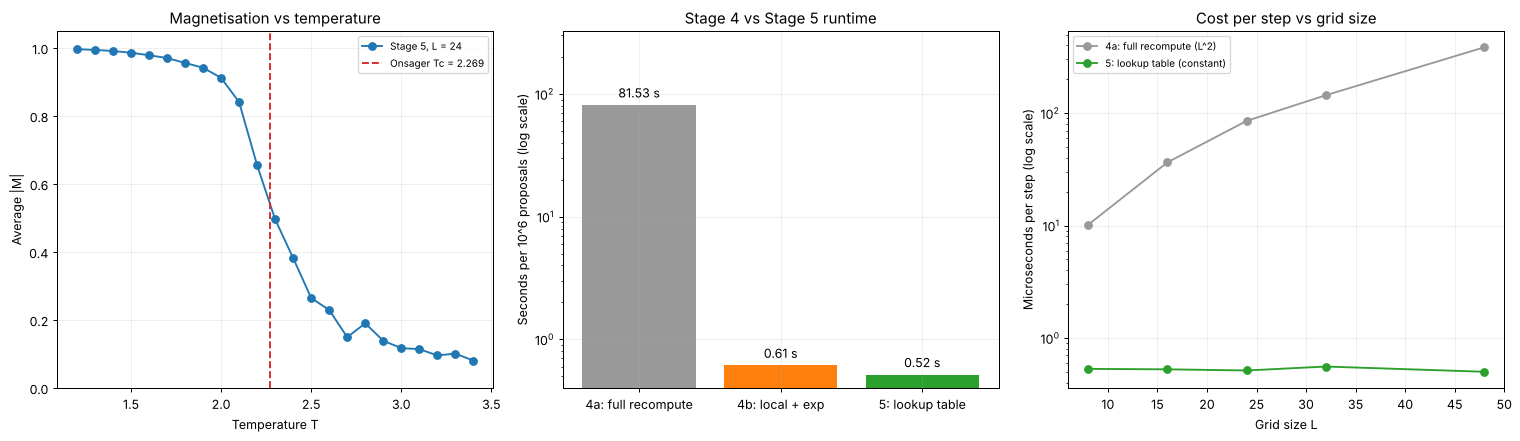

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Phase transition
axes[0].plot(temperatures, magnetisations, "o-", color="tab:blue", label="Stage 5, L = 24")
axes[0].axvline(ONSAGER_TC, color="tab:red", linestyle="--", label=f"Onsager Tc = {ONSAGER_TC:.3f}")
axes[0].set(xlabel="Temperature T", ylabel="Average |M|", title="Magnetisation vs temperature", ylim=(0, 1.05))
axes[0].legend(fontsize=8)

# 2. Runtime per million proposals
names = list(runtimes)
values = list(runtimes.values())
bars = axes[1].bar(names, values, color=["0.6", "tab:orange", "tab:green"])
axes[1].set_yscale("log")
axes[1].set_ylim(top=max(values) * 4)
axes[1].set(ylabel="Seconds per 10^6 proposals (log scale)", title="Stage 4 vs Stage 5 runtime")
for bar, value in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value * 1.15, f"{value:.2f} s", ha="center")

# 3. Cost per step as the grid grows
axes[2].plot(sizes, cost4a, "o-", color="0.6", label="4a: full recompute (L^2)")
axes[2].plot(sizes, cost5, "o-", color="tab:green", label="5: lookup table (constant)")
axes[2].set_yscale("log")
axes[2].set(xlabel="Grid size L", ylabel="Microseconds per step (log scale)", title="Cost per step vs grid size")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig("experiment1_ising_results.png", dpi=200, bbox_inches="tight")
plt.show()